In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
df=pd.read_csv("Downloads/dataset.csv")

In [4]:
df

,N,P,K,temperature,humidity,ph,rainfall,label
0,92.19,38.51,45.58,26.88,67.51,5.55,202.05,rice
1,87.72,41.94,40.07,26.76,84.98,6.23,218.04,rice
2,93.37,39.11,44.27,23.08,85.62,6.18,197.04,rice
3,85.10,46.11,42.47,24.14,77.75,6.46,205.85,rice
4,92.97,43.45,50.37,24.19,76.72,5.80,209.86,rice
...,...,...,...,...,...,...,...,...
247,100.30,24.82,29.93,22.61,70.77,5.75,160.98,coffee
248,89.05,24.62,28.03,23.20,77.51,6.71,156.08,coffee
249,89.51,26.34,28.14,21.94,82.01,5.76,160.71,coffee
250,93.80,23.76,28.42,21.96,87.03,6.30,170.52,coffee


In [13]:
le=LabelEncoder()
df["label"]=le.fit_transform(df["label"])

In [17]:
le=LabelEncoder()
for column in df.columns:
    df[column]=le.fit_transform(df[column])

In [18]:
df

,N,P,K,temperature,humidity,ph,rainfall,label
0,200,90,192,159,110,13,238,19
1,190,97,164,155,203,62,245,19
2,205,92,185,69,207,59,237,19
3,187,121,178,92,168,82,240,19
4,202,104,205,93,159,29,242,19
...,...,...,...,...,...,...,...,...
247,218,60,115,57,127,25,217,5
248,194,57,100,72,165,104,211,5
249,195,65,101,45,184,26,216,5
250,207,53,103,46,212,68,224,5


In [19]:
x=df.drop("label",axis=1)
y=df["label"]

In [20]:
x

,N,P,K,temperature,humidity,ph,rainfall
0,200,90,192,159,110,13,238
1,190,97,164,155,203,62,245
2,205,92,185,69,207,59,237
3,187,121,178,92,168,82,240
4,202,104,205,93,159,29,242
...,...,...,...,...,...,...,...
247,218,60,115,57,127,25,217
248,194,57,100,72,165,104,211
249,195,65,101,45,184,26,216
250,207,53,103,46,212,68,224


In [21]:
y

0      19
1      19
2      19
3      19
4      19
       ..
247     5
248     5
249     5
250     5
251     5
Name: label, Length: 252, dtype: int64

In [22]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [23]:
x_train,x_test

(       N    P    K  temperature  humidity   ph  rainfall
 136   64   48  102          231        33  132        99
 55    26  184   57          179        28    1       118
 204   73   38  111          137       217    3       218
 216  241   74   15          197       100   96       123
 147  120   89  121           68       111   25        69
 ..   ...  ...  ...          ...       ...  ...       ...
 106   23  169   45          106       145  132         4
 14   173  115  156          124        90  119        86
 92   134  174   58           73        97   68        76
 179   57  239  232           77        64  143       162
 102   45  180   16           95        91   63         7
 
 [201 rows x 7 columns],
        N    P    K  temperature  humidity   ph  rainfall
 165  214   29  203           42       104   34        40
 6    188  101  182          126       206   69       243
 111    7   31  142           44       148  144       175
 172   32  240  232           26        96   

In [26]:
y_train,y_test

(136    12
 55     17
 204     4
 216     6
 147     7
        ..
 106    10
 14     11
 92      2
 179     0
 102    10
 Name: label, Length: 201, dtype: int64,
 165    20
 6      19
 111    18
 172     0
 115    18
 183    15
 199    16
 235     8
 9      19
 30      3
 60     13
 218     6
 226     6
 159    20
 68     13
 148     7
 196    16
 15     11
 101    10
 24      3
 86      2
 19     11
 117    18
 124     1
 33      3
 242     5
 186    15
 219     6
 10     19
 162    20
 140    12
 96     10
 125     1
 82     14
 213     4
 25      3
 109    18
 18     11
 205     4
 182    15
 67     13
 132    12
 156    20
 143    12
 45      9
 178     0
 16     11
 66     13
 142    12
 175     0
 38      9
 Name: label, dtype: int64)

In [27]:
model=LinearRegression()

In [28]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.02,-0.03, 0. ,..., 0. , 0. ,-0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['N','P','K',...,'humidity','ph','rainfall']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,14.05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [31]:
prediction=model.predict(x)

In [32]:
prediction


array([ 9.17491199,  9.40469088,  8.12069078,  7.81215319,  7.89186572,
        8.00700929,  8.96147422,  7.51585028,  8.28147975,  7.87662214,
        9.81157614,  8.50505985,  8.43325356,  7.74441111,  9.98630611,
        9.50760652,  8.91916435,  9.60320242,  8.15890474,  9.50933562,
        9.11025466,  7.71370995,  8.2870982 ,  8.23634007,  6.05843586,
        5.67365778,  6.1272728 ,  5.07631451,  6.33590685,  6.89561356,
        6.66080254,  6.04906539,  6.8468203 ,  5.48479948,  5.95412654,
        7.95770185,  6.76182205,  7.11589238,  6.4146873 ,  4.99516104,
        7.62445102,  7.33737144,  6.15997373,  6.26431511,  5.56988035,
        7.08476064,  6.0889865 ,  6.17477737, 10.30572351,  7.55878516,
        9.55991915, 10.41292945,  8.24198788,  9.29595368, 10.37743913,
        9.7968855 ,  9.64812662, 10.82315934,  7.90877883,  9.9969453 ,
        9.75497326, 10.59098347, 10.19993245, 10.47525303, 10.98396207,
       10.50287684, 11.98792999, 10.8033021 , 12.23203851, 10.01

In [33]:
y_pred=model.predict(x_test)

In [34]:
y_pred

array([10.91866852,  8.96147422, 13.43592761,  6.01563726, 13.41448102,
       14.44335294, 10.57413129,  8.9994245 ,  7.87662214,  6.66080254,
        9.75497326, 10.00429952,  8.82066803, 14.16391629, 12.23203851,
       11.97829327, 10.09666852,  9.50760652,  8.35224095,  6.05843586,
       10.10314565,  9.50933562, 12.91719296,  5.37719773,  5.48479948,
       10.74107231, 13.13994686,  8.87002121,  9.81157614, 12.54013943,
       14.72548751, 10.40076713,  5.91404997, 12.97579207, 14.42252475,
        5.67365778, 12.70832048,  8.15890474, 13.3044559 , 15.10365064,
       10.8033021 , 13.66854629, 13.87792541, 14.2740498 ,  7.08476064,
        6.13676135,  8.91916435, 11.98792999, 13.77069638,  6.04205297,
        6.4146873 ])

In [35]:
y_test=model.predict(x_test)

In [36]:
y_test

array([10.91866852,  8.96147422, 13.43592761,  6.01563726, 13.41448102,
       14.44335294, 10.57413129,  8.9994245 ,  7.87662214,  6.66080254,
        9.75497326, 10.00429952,  8.82066803, 14.16391629, 12.23203851,
       11.97829327, 10.09666852,  9.50760652,  8.35224095,  6.05843586,
       10.10314565,  9.50933562, 12.91719296,  5.37719773,  5.48479948,
       10.74107231, 13.13994686,  8.87002121,  9.81157614, 12.54013943,
       14.72548751, 10.40076713,  5.91404997, 12.97579207, 14.42252475,
        5.67365778, 12.70832048,  8.15890474, 13.3044559 , 15.10365064,
       10.8033021 , 13.66854629, 13.87792541, 14.2740498 ,  7.08476064,
        6.13676135,  8.91916435, 11.98792999, 13.77069638,  6.04205297,
        6.4146873 ])

In [37]:
mse=mean_squared_error(y_test,y_pred)

In [38]:
mse

0.0

In [39]:
r2=r2_score(y_test,y_pred)

In [40]:
r2

1.0

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

In [44]:
df=pd.read_csv("Downloads/Cricket-all-teams-all-matches.csv")

In [45]:
df

,Team 1,Team 2,Winner,Margin,Ground,Match Date,Scorecard,Format
0,India,Pakistan,drawn,NaN,Bengaluru,"Dec 8-12, 2007",Test # 1852,Test
1,India,Pakistan,drawn,NaN,Eden Gardens,"Nov 30-Dec 4, 2007",Test # 1850,Test
2,India,Pakistan,India,6 wickets,Delhi,"Nov 22-26, 2007",Test # 1849,Test
3,Pakistan,India,Pakistan,341 runs,Karachi,"Jan 29-Feb 1, 2006",Test # 1783,Test
4,Pakistan,India,drawn,NaN,Faisalabad,"Jan 21-25, 2006",Test # 1782,Test
...,...,...,...,...,...,...,...,...
7788,Australia,ICC World XI,Australia,210 runs,Sydney,"Oct 14-17, 2005",Test # 1768,Test
7789,Australia,ICC World XI,Australia,156 runs,Melbourne (Docklands),"Oct 9, 2005",ODI # 2284,ODI
7790,Australia,ICC World XI,Australia,55 runs,Melbourne (Docklands),"Oct 7, 2005",ODI # 2283,ODI
7791,Australia,ICC World XI,Australia,93 runs,Melbourne (Docklands),"Oct 5, 2005",ODI # 2282,ODI


In [46]:
from sklearn.preprocessing import LabelEncoder

In [47]:
le1=LabelEncoder()
for column in df.columns:
    df[column]=le1.fit_transform(df[column])

In [48]:
df

,Team 1,Team 2,Winner,Margin,Ground,Match Date,Scorecard,Format
0,5,8,13,556,13,1557,6160,2
1,5,8,13,556,60,5842,6158,2
2,5,8,4,302,49,5638,6156,2
3,8,5,7,239,90,3033,6083,2
4,8,5,13,556,61,2793,6082,2
...,...,...,...,...,...,...,...,...
7788,1,4,1,125,159,6080,6066,2
7789,1,4,1,65,109,6519,1319,0
7790,1,4,1,295,109,6486,1318,0
7791,1,4,1,343,109,6456,1317,0


In [49]:
x=df.drop("Winner",axis=1)
y=df["Winner"]

In [50]:
x

,Team 1,Team 2,Margin,Ground,Match Date,Scorecard,Format
0,5,8,556,13,1557,6160,2
1,5,8,556,60,5842,6158,2
2,5,8,302,49,5638,6156,2
3,8,5,239,90,3033,6083,2
4,8,5,556,61,2793,6082,2
...,...,...,...,...,...,...,...
7788,1,4,125,159,6080,6066,2
7789,1,4,65,109,6519,1319,0
7790,1,4,295,109,6486,1318,0
7791,1,4,343,109,6456,1317,0


In [51]:
y

0       13
1       13
2        4
3        7
4       13
        ..
7788     1
7789     1
7790     1
7791     1
7792    10
Name: Winner, Length: 7793, dtype: int64

In [52]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [53]:
model1=LinearRegression()

In [54]:
model1.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0.45, 0.3 , 0.01,...,-0. ,-0. , 0.46]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Team 1','Team 2','Margin',...,'Match Date','Scorecard','Format']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.487
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [58]:
y_pred1=model1.predict(x_test)

In [59]:
y_pred1

array([8.5182991 , 5.46586502, 7.83354459, ..., 4.50976895, 7.1697666 ,
       9.45324572], shape=(1559,))

In [60]:
y_test1=model1.predict(x_test)

In [61]:
y_test1

array([8.5182991 , 5.46586502, 7.83354459, ..., 4.50976895, 7.1697666 ,
       9.45324572], shape=(1559,))

In [65]:
mse1=mean_squared_error(y_test1,y_pred1)

In [66]:
mse1

0.0

In [67]:
r2score1=r2_score(y_test1,y_pred1)

In [68]:
r2score1

1.0

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score

In [70]:
df=pd.read_csv("Downloads/boston (1).csv")

In [71]:
df

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48,22.0


In [73]:
df.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

In [74]:
x=df.drop("MEDV",axis=1)
y=df["MEDV"]

In [78]:
x.head(5)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33


In [77]:
y.head(5)

0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64

In [80]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [82]:
model2=LinearRegression()

In [83]:
model2.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-0.11, 0.03, 0.04,...,-0.92, 0.01,-0.51]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['CRIM','ZN','INDUS',...,'PTRATIO','B','LSTAT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,30.25
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [85]:
y_pred2=model2.predict(x_test)

In [86]:
y_pred2

array([28.99672362, 36.02556534, 14.81694405, 25.03197915, 18.76987992,
       23.25442929, 17.66253818, 14.34119   , 23.01320703, 20.63245597,
       24.90850512, 18.63883645, -6.08842184, 21.75834668, 19.23922576,
       26.19319733, 20.64773313,  5.79472718, 40.50033966, 17.61289074,
       27.24909479, 30.06625441, 11.34179277, 24.16077616, 17.86058499,
       15.83609765, 22.78148106, 14.57704449, 22.43626052, 19.19631835,
       22.43383455, 25.21979081, 25.93909562, 17.70162434, 16.76911711,
       16.95125411, 31.23340153, 20.13246729, 23.76579011, 24.6322925 ,
       13.94204955, 32.25576301, 42.67251161, 17.32745046, 27.27618614,
       16.99310991, 14.07009109, 25.90341861, 20.29485982, 29.95339638,
       21.28860173, 34.34451856, 16.04739105, 26.22562412, 39.53939798,
       22.57950697, 18.84531367, 32.72531661, 25.0673037 , 12.88628956,
       22.68221908, 30.48287757, 31.52626806, 15.90148607, 20.22094826,
       16.71089812, 20.52384893, 25.96356264, 30.61607978, 11.59

In [89]:
y_test2=model2.predict(x_test)

In [90]:
y_test2

array([28.99672362, 36.02556534, 14.81694405, 25.03197915, 18.76987992,
       23.25442929, 17.66253818, 14.34119   , 23.01320703, 20.63245597,
       24.90850512, 18.63883645, -6.08842184, 21.75834668, 19.23922576,
       26.19319733, 20.64773313,  5.79472718, 40.50033966, 17.61289074,
       27.24909479, 30.06625441, 11.34179277, 24.16077616, 17.86058499,
       15.83609765, 22.78148106, 14.57704449, 22.43626052, 19.19631835,
       22.43383455, 25.21979081, 25.93909562, 17.70162434, 16.76911711,
       16.95125411, 31.23340153, 20.13246729, 23.76579011, 24.6322925 ,
       13.94204955, 32.25576301, 42.67251161, 17.32745046, 27.27618614,
       16.99310991, 14.07009109, 25.90341861, 20.29485982, 29.95339638,
       21.28860173, 34.34451856, 16.04739105, 26.22562412, 39.53939798,
       22.57950697, 18.84531367, 32.72531661, 25.0673037 , 12.88628956,
       22.68221908, 30.48287757, 31.52626806, 15.90148607, 20.22094826,
       16.71089812, 20.52384893, 25.96356264, 30.61607978, 11.59

In [91]:
mse2=mean_squared_error(y_test2,y_pred2)

In [92]:
mse2

0.0

In [93]:
r2=r2_score(y_test2,y_pred2)

In [94]:
r2

1.0

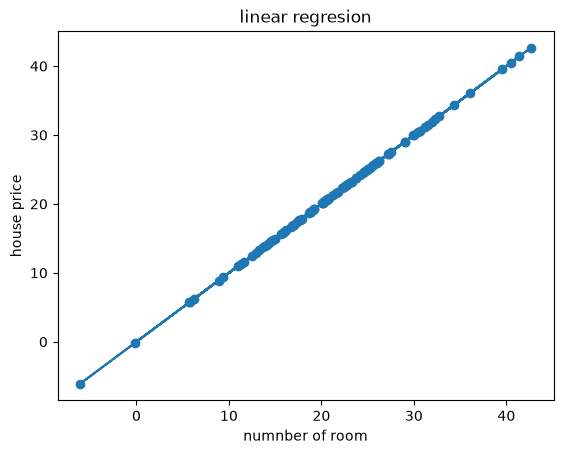

In [95]:
plt.scatter(y_test2,y_pred2)
plt.plot(y_test2,y_pred2)
plt.title("linear regresion")
plt.xlabel("numnber of room")
plt.ylabel("house price")
plt.show()